TokaMaker Example: Analytic Solov'ev equilibrium {#doc_tMaker_fixed_ex3}
==========
In this example we show how to use TokaMaker to compute a fixed-boundary Solov'ev equilibrium and compare the result to the analytic solution. This case is one of the analytic verification tests described in the TokaMaker paper ([C. Hansen et al., Comput. Phys. Commun. 298 (2024) 109111](https://doi.org/10.1016/j.cpc.2024.109111), section 4.1.2) and is also part of the TokaMaker regression tests. The example covers:
 1. Defining the analytic Solov'ev solution and using it to set a Dirichlet boundary condition
 2. Configuring flat profiles over the full computational domain to reproduce the Solov'ev source terms
 3. Comparing the TokaMaker and analytic flux, X-point, and O-point locations
 4. Showing that the solution is exact (to roundoff) when using 4th order elements

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

For meshing we will use the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain "gs_Domain" class to build a 2D triangular grid suitable for Grad-Shafranov equilibria. This class uses the [triangle code](https://www.cs.cmu.edu/~quake/triangle.html) through a simple internal python wrapper within OFT.

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import gs_Domain

## Define analytic solution

The Solov'ev equilibria are a family of analytic solutions to the Grad-Shafranov equation
$$
\Delta^* \psi = -\frac{1}{2}\frac{\partial F^2}{\partial \psi} - \mu_0 R^2 \frac{\partial P}{\partial \psi}
$$
for the case where both source terms are constant, with $\mu_0 \frac{\partial P}{\partial \psi} = -a$ and $\frac{\partial F^2}{\partial \psi} = -2 b R_0^2$. In this case the solution is a quartic function of the form
$$
\psi(R,Z) = \frac{1}{2}(b+c_0)R_0^2 Z^2 + c_0 R_0 \zeta Z^2 + \frac{1}{2}(a-c_0)R_0^2 \zeta^2,
$$
where $c_0$ is an additional free constant and $\zeta = \frac{R^2-R_0^2}{2R_0}$.

Following [T. Xu and R. Fitzpatrick, Nucl. Fusion 59 (2019) 064002](https://doi.org/10.1088/1741-4326/ab1ce3) we use $R_0 = 1.0$, $a = 1.2$, $b = -1.0$, and $c_0 = 1.1$, which yields an up-down symmetric equilibrium with a magnetic axis (O-point) at $(R_0,0)$ and two X-points located at
$$
R_X = \sqrt{R_0^2 - \frac{(b+c_0)R_0^2}{c_0}}, \quad Z_X = \pm R_0\sqrt{\frac{(b+c_0)(a-c_0)}{2 c_0^2}}.
$$

Below we define these parameters and a function to evaluate $\psi$ for the analytic solution at a set of points.

In [3]:
# Solov'ev parameters
R0 = 1.0
a = 1.2
b = -1.0
c0 = 1.1

def solovev_psi(r,z):
    '''! Evaluate poloidal flux for analytic Solov'ev equilibrium

    @param r Radial positions
    @param z Vertical positions
    @result Poloidal flux at each point
    '''
    zeta = (np.power(r,2)-R0*R0)/(2.0*R0)
    return (b+c0)*R0*R0*np.power(z,2)/2.0 + c0*R0*zeta*np.power(z,2) + (a-c0)*R0*R0*np.power(zeta,2)/2.0

# Analytic X-point (upper) and O-point locations
zeta_x = -(b+c0)*R0/(2.0*c0)
rz_x = np.r_[np.sqrt(2.0*R0*zeta_x+R0*R0), R0*np.sqrt((b+c0)*(a-c0)/(2.0*c0*c0))]
rz_o = np.r_[R0, 0.0]
psi_x = solovev_psi(rz_x[0],rz_x[1])
print('Analytic X-points  = ({0:.6f}, +/-{1:.6f})'.format(*rz_x))
print('Analytic O-point   = ({0:.6f}, {1:.6f})'.format(*rz_o))
print('Flux at separatrix = {0:.6E}'.format(psi_x))

Analytic X-points  = (0.953463, +/-0.064282)
Analytic O-point   = (1.000000, 0.000000)
Flux at separatrix = 1.033058E-04


## Create mesh
First we define a target size to set the resolution in our grid. This variable will be used later and represent the target edge size within our mesh, where units are in meters. In this case we use a resolution of 0.75 cm (20 cells in the vertical direction), which matches the case shown in Fig. 7 of the TokaMaker paper.

### Define regions and geometry
As the Solov'ev solution is not bounded by a closed flux surface we are free to choose any computational domain. Here we use a simple rectangle centered at $(R_0,0)$ with a width of 12 cm and a height of 15 cm, which contains both X-points. In this case we only have one region, which is named `plasma` and is of type `plasma`.

In [4]:
mesh_dx = 0.0075
# Create a G-S domain
gs_mesh = gs_Domain()
# Define region information for mesh
gs_mesh.define_region('plasma',mesh_dx,'plasma')
# Define geometry for mesh
gs_mesh.add_rectangle(R0,0.0,0.12,0.15,'plasma')

### Generate mesh
Now we generate the actual mesh using the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain.build_mesh "build_mesh" method. This step may take a few moments as [triangle](https://www.cs.cmu.edu/~quake/triangle.html) generates the mesh.

In [5]:
mesh_pts, mesh_lc, mesh_reg = gs_mesh.build_mesh()

Assembling regions:
  # of unique points    = 72
  # of unique segments  = 4
Generating mesh with Triangle:
  # of points  = 525
  # of cells   = 976
  # of regions = 1


### Plot resulting regions and grid
We now plot the mesh to inspect proper generation.

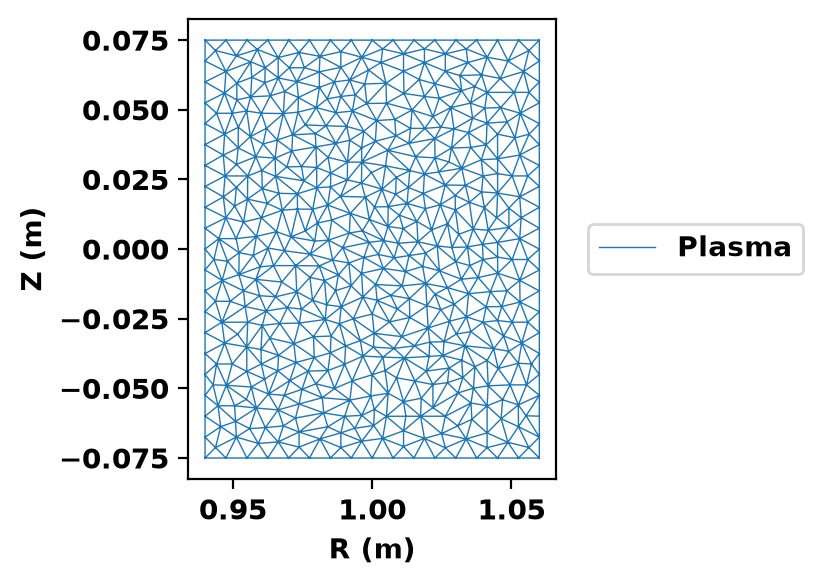

In [6]:
fig, ax = plt.subplots(1,1,figsize=(4,5),constrained_layout=True)
gs_mesh.plot_mesh(fig,ax)

## Compute equilibrium

### Initialize TokaMaker object
We now create a \ref OpenFUSIONToolkit.OFT_env "OFT_env" instance for execution using two threads and a \ref OpenFUSIONToolkit.TokaMaker.TokaMaker "TokaMaker" instance to use for equilibrium calculations. Note at present only a single `TokaMaker` instance can be used per python kernel, so this command should only be called **once** in a given Jupyter notebook or python script. In the future this restriction may be relaxed.

In [7]:
myOFT = OFT_env(nthreads=2)
mygs = TokaMaker(myOFT)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/



Base release:        v26.9
Development branch:  claude/tokamaker-solovev-example-8c907d
Revision id:         7caa53b2

Parallelization Info:
  # of MPI tasks      =    1
  # of NUMA nodes     =    1
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



### Load mesh into TokaMaker
Now we load the mesh generated above using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_mesh "setup_mesh" and set the code to operate in fixed boundary mode by setting the `free_boundary` setting to False. Finally, we call \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup "setup" to setup the required solver objects. During this call we specify the desired element order (min=2, max=4) and the toroidal field through F0 = B0*R0. F0 only sets the vacuum toroidal field and does not affect $\psi$ for this case.

Unlike the other fixed-boundary examples, the Solov'ev solution has nonzero source terms everywhere in the domain, including outside the separatrix. So we also set `full_domain=True`, which tells TokaMaker to apply the $F*F'$ and $P'$ source terms over the entire plasma region instead of only within the last closed flux surface.

In [8]:
mygs.setup_mesh(mesh_pts,mesh_lc)
mygs.settings.free_boundary = False
mygs.setup(order=2,F0=1.0,full_domain=True)


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.800E-02
    # of points  =     525
    # of edges   =    1500
    # of cells   =     976
    # of boundary points =      72
    # of boundary edges  =      72
    # of boundary cells  =      72
  Resolution statistics:
    hmin =  4.705E-03
    hrms =  6.874E-03
    hmax =  1.119E-02
  Surface grounded at vertex      27


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1



### Define flux profiles
To reproduce the constant Solov'ev source terms we use `flat` profiles for both $F*F'$ and $P'$ and set the profile scale factors directly, through the \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.p_scale "p_scale" and \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.ffp_scale "ffp_scale" properties, instead of using global targets (eg. Ip). Here `p_scale` corresponds to $\mu_0 \frac{\partial P}{\partial \psi}$ and `ffp_scale` corresponds to $\frac{\partial F^2}{\partial \psi}$.

**Note:** The sign convention for $\psi$ in TokaMaker is opposite of the one used above (TokaMaker's $\psi$ decreases moving away from the magnetic axis), so $\psi_{TokaMaker} = -\psi_{Solov'ev}$ and the scale factors have the opposite sign of the source terms in the definition above.

In [9]:
mygs.set_profiles(ffp_prof={'type': 'flat'},pp_prof={'type': 'flat'})
mygs.p_scale = a
mygs.ffp_scale = 2.0*b*R0*R0

### Set boundary condition
Before running a calculation for the first time we must initialize the flux function $\psi$, which is done using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.init_psi "init_psi". For this case we then overwrite $\psi$ with the analytic solution using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_psi "set_psi", which is evaluated at each node of the mesh (`mygs.r`). In fixed-boundary mode the values of $\psi$ on the boundary are held fixed during the solve, so this step sets the Dirichlet boundary condition for the analytic solution (as well as the initial guess in the interior).

In [10]:
mygs.init_psi()
psi_analytic = solovev_psi(mygs.r[:,0],mygs.r[:,1])
mygs.set_psi(-psi_analytic)

### Compute a fixed-boundary equilibrium
Now we can compute the equilibrium by running \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.solve "solve". As the analytic solution is known exactly, we tighten the nonlinear convergence tolerance so that the error is dominated by the spatial discretization. Settings changed after `setup` must be passed to TokaMaker using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.update_settings "update_settings".

In [11]:
mygs.settings.nl_tol = 1.E-14
mygs.update_settings()
_ = mygs.solve()

Starting non-linear GS solver
     1 -2.0000E+00  1.2000E+00  7.6125E-08  1.0000E+00  3.4187E-05  0.0000E+00
     2 -2.0000E+00  1.2000E+00  1.5225E-08  1.0000E+00  3.4760E-05  0.0000E+00
     3 -2.0000E+00  1.2000E+00  3.0450E-09  1.0000E+00  3.4875E-05  0.0000E+00


     4 -2.0000E+00  1.2000E+00  6.0900E-10  1.0000E+00  3.4899E-05  0.0000E+00
     5 -2.0000E+00  1.2000E+00  1.2180E-10  1.0000E+00  3.4903E-05  0.0000E+00
     6 -2.0000E+00  1.2000E+00  2.4360E-11  1.0000E+00  3.4904E-05  0.0000E+00
     7 -2.0000E+00  1.2000E+00  4.8720E-12  1.0000E+00  3.4904E-05  0.0000E+00
     8 -2.0000E+00  1.2000E+00  9.7440E-13  1.0000E+00  3.4904E-05  0.0000E+00
     9 -2.0000E+00  1.2000E+00  1.9488E-13  1.0000E+00  3.4904E-05  0.0000E+00
    10 -2.0000E+00  1.2000E+00  3.8977E-14  1.0000E+00  3.4904E-05  0.0000E+00
    11 -2.0000E+00  1.2000E+00  7.7966E-15  1.0000E+00  3.4904E-05  0.0000E+00
 Timing:   1.8587999977171421E-002
   Source:     6.6759991459548473E-003
   Solve:      2.4449988268315792E-003
   Boundary:   1.3930001296103001E-003
   Other:      8.0740018747746944E-003


### Print equilibrium information
After computing the equilibrium, basic parameters can be displayed using the \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.print_info "print_info" method. For access to these quantities as variables instead the \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.get_stats "get_stats" can be used.

**Note:** As the Solov'ev solution has nonzero source terms everywhere, profile-based quantities (eg. pressure, stored energy, and $\beta$) are evaluated using the `flat` profiles relative to $\psi = 0$, instead of the LCFS, and should not be interpreted physically for this case.

In [12]:
mygs.print_info()

Equilibrium Statistics:
  Topology                =   Diverted
  Toroidal Current [A]    =    1.1083E+03
  Current Centroid [m]    =    0.997 -0.000
  Magnetic Axis [m]       =    1.000  0.000
  Elongation              =    1.406 (U:  1.403, L:  1.410)
  Triangularity           =    0.994 (U:  0.989, L:  1.000)
  Plasma Volume [m^3]     =    0.049
  q_0, q_95               =   10.054 16.926
  Plasma Pressure [Pa]    =   Axis: -1.0147E-01, Peak: -1.0147E-01
  Stored Energy [J]       =   -3.9232E+00
  <Beta_pol> [%]          =   -912.9577
  <Beta_tor> [%]          =   -0.0134
  <Beta_n>   [%]          =   -0.5545
  Diamagnetic flux [Wb]   =    4.4848E-07
  Toroidal flux [Wb]      =    7.9459E-03
  l_i                     =    0.6010


## Compare with analytic solution

### Compare flux and critical points
We now retrieve the (unnormalized) flux using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.get_psi "get_psi" and the X-points using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.get_xpoints "get_xpoints". The location of the magnetic axis is available from the `o_point` attribute. These are then compared to the analytic values from above.

In [13]:
psi_TM = -mygs.get_psi(False) # Flip sign to match Solov'ev convention
x_points, _ = mygs.get_xpoints()
x_points = x_points[np.argsort(x_points[:,1]),:] # Sort as [lower, upper]
psi_err = psi_TM-psi_analytic
print('Max error in psi (relative to separatrix flux) = {0:.4E}'.format(abs(psi_err).max()/psi_x))
print('Error in O-point location                      = {0:.4E} [m]'.format(np.linalg.norm(mygs.o_point-rz_o)))
print('Error in lower X-point location                = {0:.4E} [m]'.format(np.linalg.norm(x_points[0,:]-rz_x*[1.0,-1.0])))
print('Error in upper X-point location                = {0:.4E} [m]'.format(np.linalg.norm(x_points[1,:]-rz_x)))

Max error in psi (relative to separatrix flux) = 7.2898E-05
Error in O-point location                      = 3.8923E-05 [m]
Error in lower X-point location                = 1.1828E-05 [m]
Error in upper X-point location                = 3.7416E-05 [m]


### Plot flux surfaces and error
Next we plot the flux surfaces from TokaMaker (red) and the analytic solution (black), including the separatrix passing through the X-points, along with the error in $\psi$ across the domain. The X-points and magnetic axis found by TokaMaker are shown with green markers. As we will repeat this comparison below, the plotting is wrapped in a simple helper function. As in the TokaMaker paper, the flux surfaces agree well and the error is small (less than $10^{-4}$ of the separatrix flux) throughout the domain, going to zero on the boundary where the Dirichlet BC is applied.

**Note:** In the Solov'ev solution $\frac{\partial P}{\partial \psi}$, $\frac{\partial F^2}{\partial \psi}$, and $J_{\phi}$ are all nonzero everywhere in space, which is non-physical for a real system. So while the solution may appear to be free-boundary, it is not in the sense of interest for application, as a Dirichlet BC is applied using the analytic $\psi$.

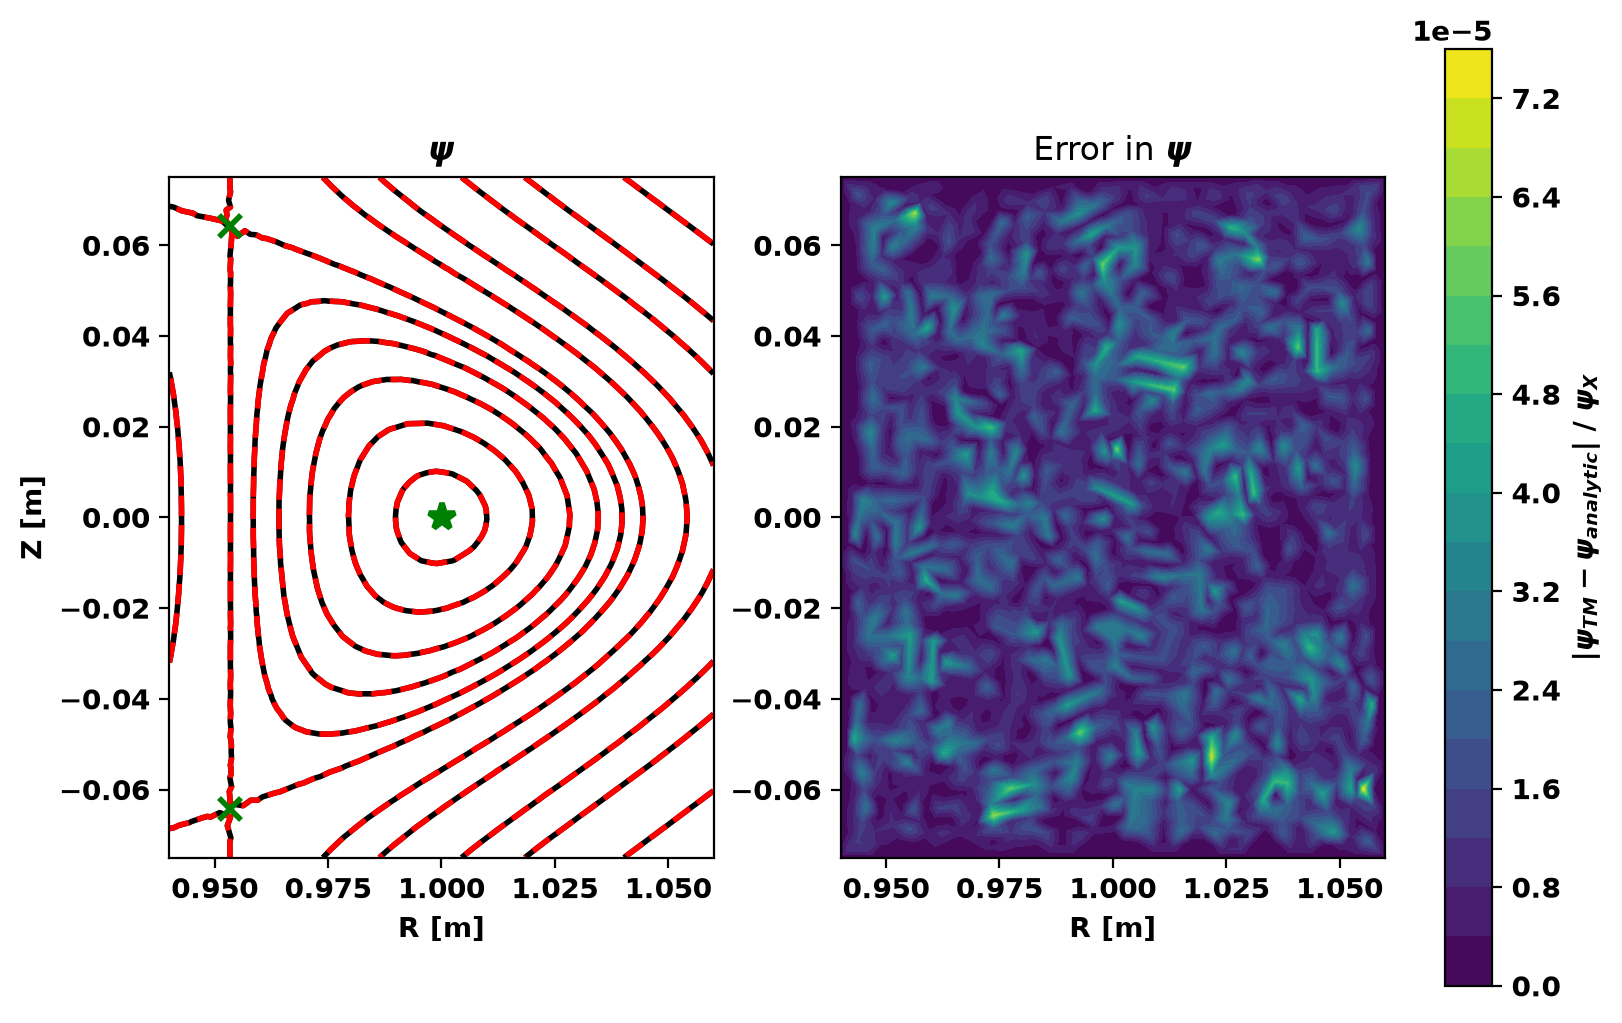

In [14]:
def plot_comparison(psi_TM,psi_analytic,x_points,o_point):
    '''! Plot flux surfaces and error for TokaMaker and analytic Solov'ev solutions

    @param psi_TM TokaMaker flux on mesh nodes (Solov'ev sign convention)
    @param psi_analytic Analytic flux on mesh nodes
    @param x_points X-point locations from TokaMaker
    @param o_point O-point location from TokaMaker
    '''
    fig, ax = plt.subplots(1,2,figsize=(8,5),constrained_layout=True)
    levels = psi_x*np.r_[0.05,0.2,0.4,0.6,0.8,1.0,1.5,2.0,3.0,4.0,6.0]
    for ax_tmp in ax:
        ax_tmp.set_aspect('equal','box')
        ax_tmp.set_xlabel('R [m]')
    ax[0].set_ylabel('Z [m]')
    # Plot flux surfaces
    ax[0].tricontour(mygs.r[:,0],mygs.r[:,1],mygs.lc,psi_analytic,levels=levels,colors='k')
    ax[0].tricontour(mygs.r[:,0],mygs.r[:,1],mygs.lc,psi_TM,levels=levels,colors='r',linestyles='--')
    ax[0].plot(x_points[:,0],x_points[:,1],'gx',markersize=8)
    ax[0].plot(o_point[0],o_point[1],'g*',markersize=10)
    ax[0].set_title(r'$\psi$')
    # Plot error in psi
    clf = ax[1].tricontourf(mygs.r[:,0],mygs.r[:,1],mygs.lc,abs(psi_TM-psi_analytic)/psi_x,levels=20)
    fig.colorbar(clf,ax=ax[1],label=r'$|\psi_{TM}-\psi_{analytic}|$ / $\psi_X$')
    ax[1].set_title(r'Error in $\psi$')

plot_comparison(psi_TM,psi_analytic,x_points,mygs.o_point)

## Exact solution with higher-order elements
As the Solov'ev solution is a quartic polynomial in $R$ and $Z$, it can be represented exactly using 4th order finite elements. So if we recompute the equilibrium using `order=4` the TokaMaker solution should match the analytic solution to within roundoff error, independent of the mesh resolution. This is also why results for $p_d > 3$ are not shown in the convergence study (Fig. 8) of the TokaMaker paper.

### Recompute equilibrium with `order=4`
To change the element order, \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.reset "reset" must first be called to clear the prior representation and prepare TokaMaker to accept a new configuration. We then repeat the steps above using the same mesh, but with `order=4` in the call to \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup "setup".

**Note:** `reset` also restores the default settings, so `free_boundary` and `nl_tol` must be set again.

In [15]:
mygs.reset()
mygs.setup_mesh(mesh_pts,mesh_lc)
mygs.settings.free_boundary = False
mygs.settings.nl_tol = 1.E-14
mygs.setup(order=4,F0=1.0,full_domain=True)
# Set profiles and boundary condition
mygs.set_profiles(ffp_prof={'type': 'flat'},pp_prof={'type': 'flat'})
mygs.p_scale = a
mygs.ffp_scale = 2.0*b*R0*R0
mygs.init_psi()
psi_analytic = solovev_psi(mygs.r[:,0],mygs.r[:,1])
mygs.set_psi(-psi_analytic)
_ = mygs.solve()


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.800E-02
    # of points  =     525
    # of edges   =    1500
    # of cells   =     976
    # of boundary points =      72
    # of boundary edges  =      72
    # of boundary cells  =      72
  Resolution statistics:
    hmin =  4.705E-03
    hrms =  6.874E-03
    hmax =  1.119E-02
  Surface grounded at vertex      27


**** Creating Lagrange FE space
  Order  =    4
  Minlev =   -1

Starting non-linear GS solver
     1 -2.0000E+00  1.2000E+00  1.3021E-16  1.0000E+00  1.3478E-15  0.0000E+00
 Timing:   9.1369999572634697E-003
   Source:     6.8939998745918274E-003
   Solve:      6.2600011005997658E-004
   Boundary:   2.9799994081258774E-004
   Other:      1.3190000317990780E-003


### Compare with analytic solution
Comparing with the analytic solution as above, we now see that the errors in $\psi$ and the X- and O-point locations are at the level of roundoff error, confirming that the 4th order solution is exact.

In [16]:
psi_TM = -mygs.get_psi(False) # Flip sign to match Solov'ev convention
x_points, _ = mygs.get_xpoints()
x_points = x_points[np.argsort(x_points[:,1]),:] # Sort as [lower, upper]
psi_err = psi_TM-psi_analytic
print('Max error in psi (relative to separatrix flux) = {0:.4E}'.format(abs(psi_err).max()/psi_x))
print('Error in O-point location                      = {0:.4E} [m]'.format(np.linalg.norm(mygs.o_point-rz_o)))
print('Error in lower X-point location                = {0:.4E} [m]'.format(np.linalg.norm(x_points[0,:]-rz_x*[1.0,-1.0])))
print('Error in upper X-point location                = {0:.4E} [m]'.format(np.linalg.norm(x_points[1,:]-rz_x)))

Max error in psi (relative to separatrix flux) = 2.0273E-12
Error in O-point location                      = 1.3149E-12 [m]
Error in lower X-point location                = 1.1742E-12 [m]
Error in upper X-point location                = 1.6422E-13 [m]


### Plot flux surfaces and error
Plotting the flux surfaces and error for the 4th order solution shows that the error is now at the level of roundoff error throughout the domain.

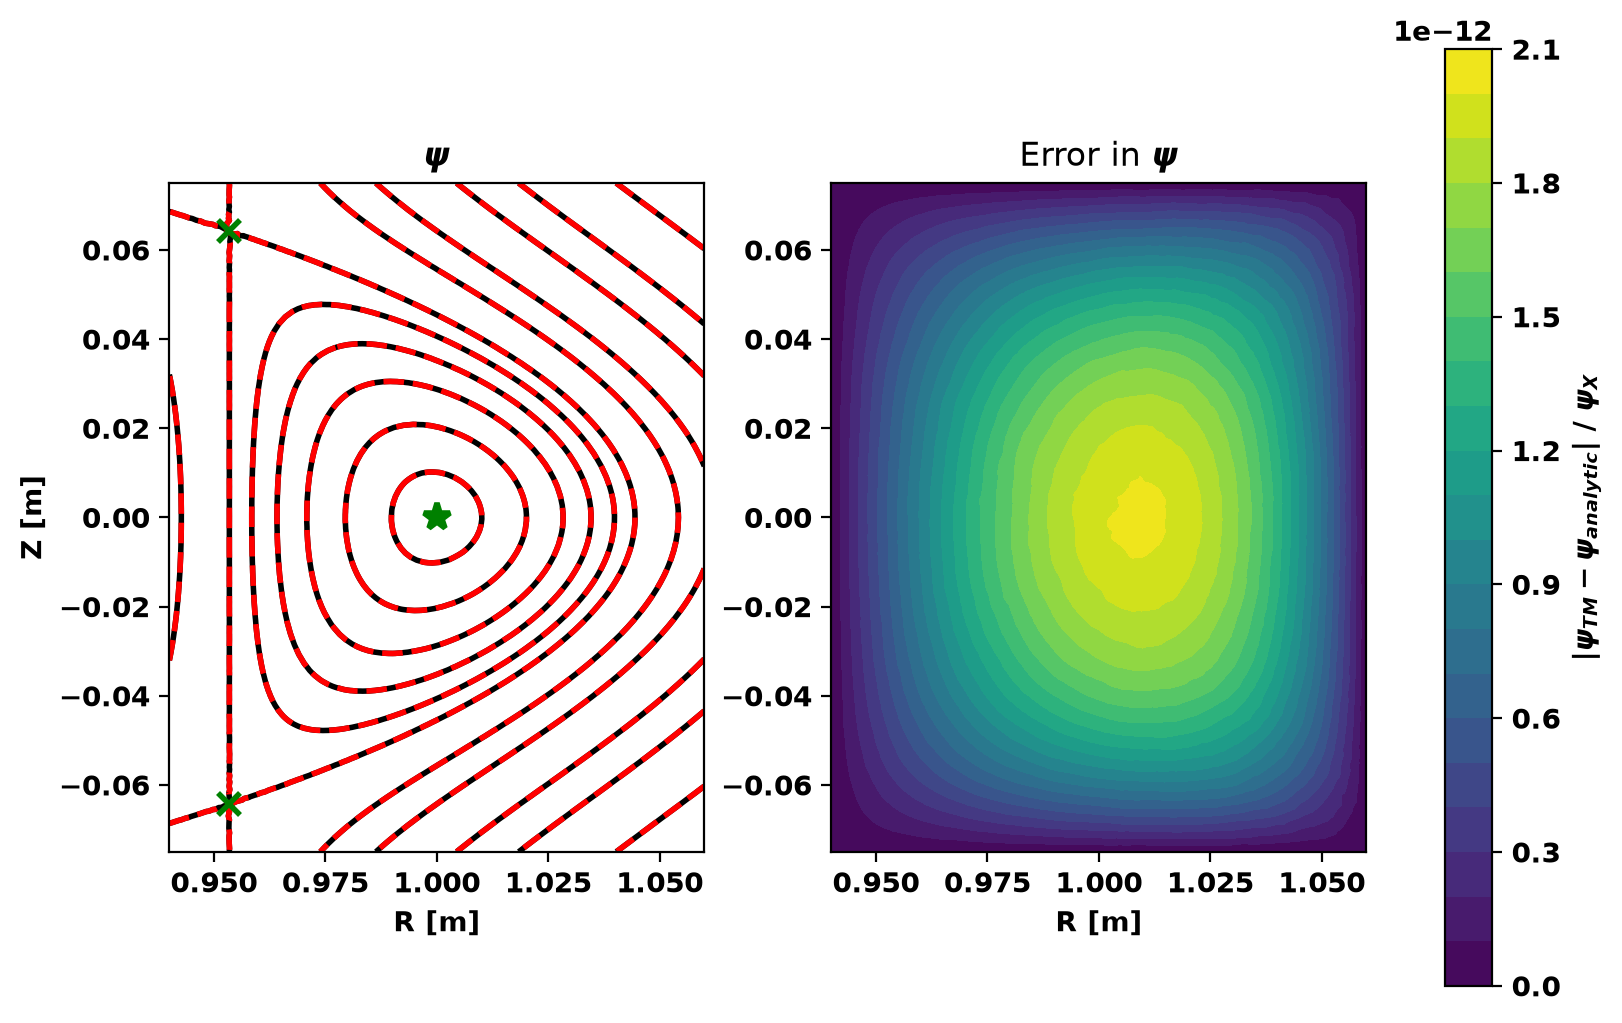

In [17]:
plot_comparison(psi_TM,psi_analytic,x_points,mygs.o_point)